# Fase 2 — Entendimento dos Dados

O objetivo desta fase é acessar, quantificar e qualificar a matéria-prima disponível, para evitar surpresas na modelagem. Checklist do guia:

1. Coletar os dados iniciais
2. Descrever quantidade e qualidade (volume, tipos de valores, códigos)
3. Explorar os dados (gráficos, hipóteses iniciais)
4. Verificar a qualidade (erros, dados omissos, inconsistências)

Nesta fase os dados são apenas observados. Nenhuma correção é feita aqui; os problemas encontrados são tratados na Fase 3.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

RAIZ = Path("..").resolve()
COR = "#2f6fab"

## 1. Coleta dos dados iniciais

- **Fonte:** *Telco Customer Churn*, amostra de dados da IBM publicada no Kaggle (`blastchar/telco-customer-churn`).
- **Arquivo:** `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv`, mantido sem alterações.
- **Granularidade:** uma linha por cliente.
- Não há outras fontes (logs, tabelas de atendimento, histórico de faturas). Tudo o que o projeto sabe sobre o cliente está nesta tabela.

In [2]:
df = pd.read_csv(RAIZ / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(f"{df.shape[0]:,} linhas e {df.shape[1]} colunas")
df.head()

7,043 linhas e 21 colunas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Descrição dos dados

### Dicionário de dados

| Grupo | Coluna | Significado |
|---|---|---|
| Identificação | `customerID` | Código único do cliente |
| Perfil | `gender` | Gênero |
| Perfil | `SeniorCitizen` | Cliente idoso (1 = sim, 0 = não) |
| Perfil | `Partner` | Tem cônjuge/parceiro |
| Perfil | `Dependents` | Tem dependentes |
| Relacionamento | `tenure` | Meses de permanência na operadora |
| Serviços | `PhoneService`, `MultipleLines` | Telefonia e múltiplas linhas |
| Serviços | `InternetService` | Tipo de internet (DSL, fibra ou nenhuma) |
| Serviços | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport` | Serviços adicionais de proteção e suporte |
| Serviços | `StreamingTV`, `StreamingMovies` | Serviços de streaming |
| Contrato | `Contract` | Tipo de contrato (mensal, um ano, dois anos) |
| Contrato | `PaperlessBilling` | Fatura digital |
| Contrato | `PaymentMethod` | Forma de pagamento |
| Cobrança | `MonthlyCharges` | Valor mensal cobrado |
| Cobrança | `TotalCharges` | Valor total já cobrado |
| **Alvo** | `Churn` | O cliente cancelou (Yes/No) |

In [3]:
resumo = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_distintos": df.nunique(),
    "nulos": df.isna().sum(),
    "exemplo": df.iloc[0].astype(str),
})
resumo

,tipo,valores_distintos,nulos,exemplo
customerID,str,7043,0,7590-VHVEG
gender,str,2,0,Female
SeniorCitizen,int64,2,0,0
Partner,str,2,0,Yes
Dependents,str,2,0,No
tenure,int64,73,0,1
PhoneService,str,2,0,No
MultipleLines,str,3,0,No phone service
InternetService,str,3,0,DSL
OnlineSecurity,str,3,0,No


In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
categoricas = [c for c in df.columns if c not in ("customerID", "tenure", "MonthlyCharges", "TotalCharges")]
for coluna in categoricas:
    print(f"{coluna:17s} {sorted(df[coluna].astype(str).unique())}")

gender            ['Female', 'Male']
SeniorCitizen     ['0', '1']
Partner           ['No', 'Yes']
Dependents        ['No', 'Yes']
PhoneService      ['No', 'Yes']
MultipleLines     ['No', 'No phone service', 'Yes']
InternetService   ['DSL', 'Fiber optic', 'No']
OnlineSecurity    ['No', 'No internet service', 'Yes']
OnlineBackup      ['No', 'No internet service', 'Yes']
DeviceProtection  ['No', 'No internet service', 'Yes']
TechSupport       ['No', 'No internet service', 'Yes']
StreamingTV       ['No', 'No internet service', 'Yes']
StreamingMovies   ['No', 'No internet service', 'Yes']
Contract          ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  ['No', 'Yes']
PaymentMethod     ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn             ['No', 'Yes']


**Primeiras observações**

- São 7.043 clientes e 21 colunas: 1 identificador, 19 atributos e 1 alvo.
- `TotalCharges` deveria ser numérica, mas foi lida como texto. Isso indica algum valor não numérico na coluna.
- `SeniorCitizen` usa 0/1, enquanto todas as outras colunas binárias usam Yes/No.
- Seis colunas de serviços têm um terceiro valor, "No internet service", e `MultipleLines` tem "No phone service".

## 3. Exploração dos dados

### 3.1 Variável-alvo

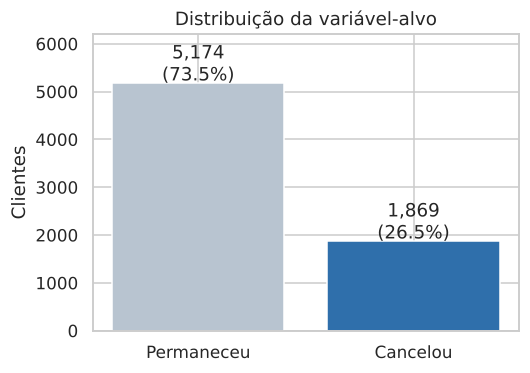

In [6]:
contagem = df["Churn"].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Permaneceu", "Cancelou"], contagem[["No", "Yes"]], color=["#b8c4d0", COR])
for i, v in enumerate(contagem[["No", "Yes"]]):
    ax.text(i, v + 60, f"{v:,}\n({v / len(df):.1%})", ha="center")
ax.set_ylim(0, 6200)
ax.set_ylabel("Clientes")
ax.set_title("Distribuição da variável-alvo")
plt.show()

As classes são desbalanceadas: 73,5% permaneceram e 26,5% cancelaram. Um modelo que respondesse "ninguém cancela" acertaria 73,5% dos casos sem ser útil. Por isso a acurácia não será a métrica principal.

### 3.2 Taxa de cancelamento por atributo categórico

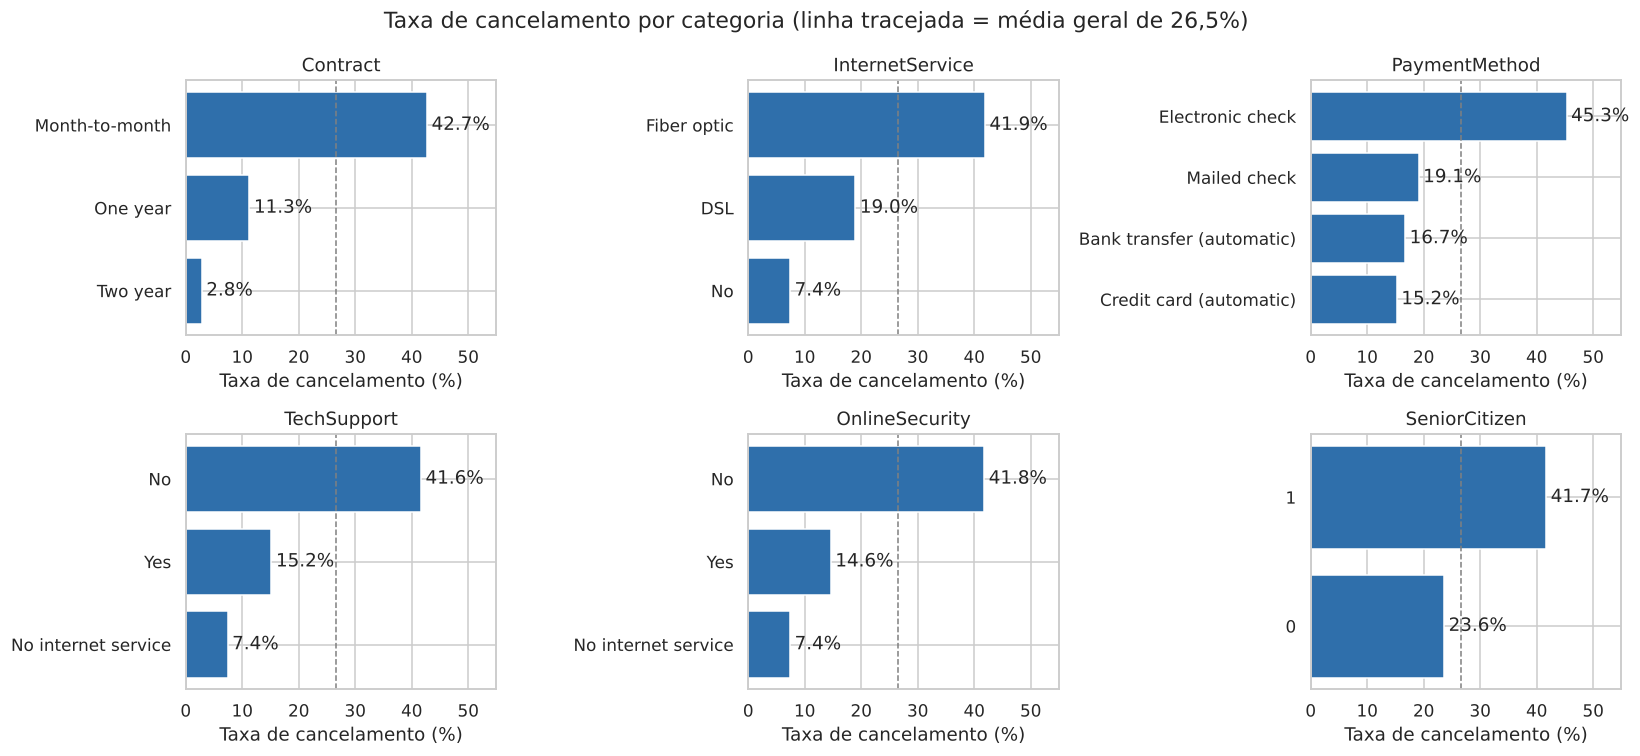

In [7]:
def taxa_churn(coluna):
    return (df.groupby(coluna)["Churn"].apply(lambda s: (s == "Yes").mean()) * 100).sort_values()

colunas = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "SeniorCitizen"]
media = (df["Churn"] == "Yes").mean() * 100

fig, eixos = plt.subplots(2, 3, figsize=(15, 7))
for ax, coluna in zip(eixos.ravel(), colunas):
    taxas = taxa_churn(coluna)
    ax.barh(taxas.index.astype(str), taxas.values, color=COR)
    ax.axvline(media, color="gray", linestyle="--", linewidth=1)
    for i, v in enumerate(taxas.values):
        ax.text(v + 0.8, i, f"{v:.1f}%", va="center")
    ax.set_xlim(0, 55)
    ax.set_title(coluna)
    ax.set_xlabel("Taxa de cancelamento (%)")
fig.suptitle("Taxa de cancelamento por categoria (linha tracejada = média geral de 26,5%)")
plt.tight_layout()
plt.show()

In [8]:
tabela = pd.concat(
    {c: taxa_churn(c).round(1) for c in ["gender", "Partner", "Dependents", "PhoneService", "PaperlessBilling"]}
).rename("taxa_churn_%").to_frame()
tabela

taxa_churn_%
gender           Male            26.2
                 Female          26.9
Partner          Yes             19.7
                 No              33.0
Dependents       Yes             15.5
                 No              31.3
PhoneService     No              24.9
                 Yes             26.7
PaperlessBilling No              16.3
                 Yes             33.6

### 3.3 Atributos numéricos

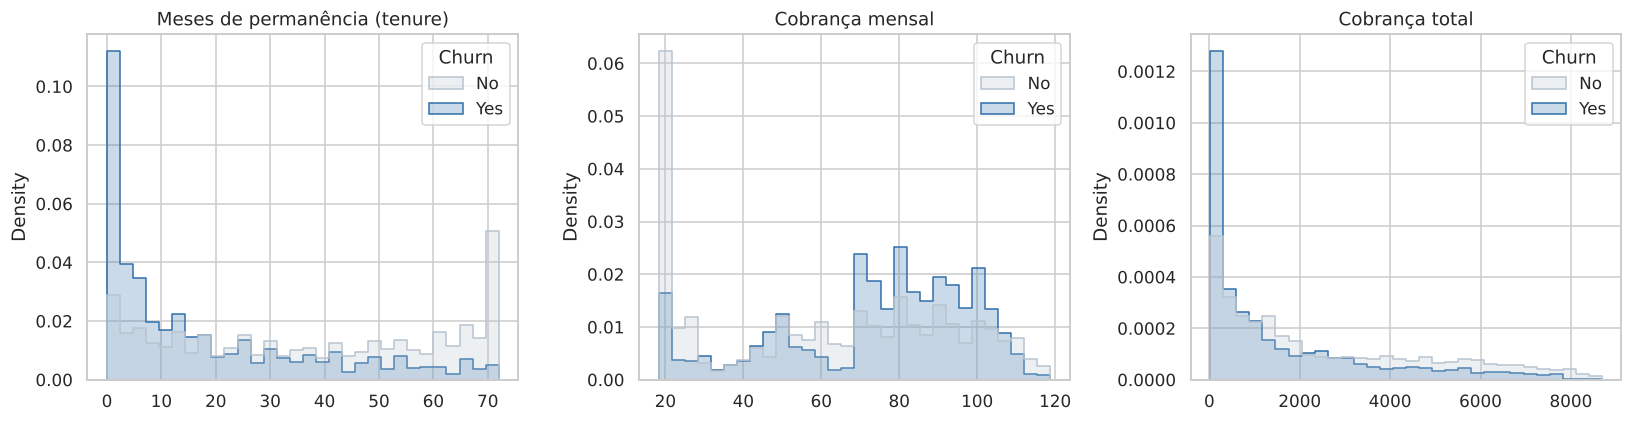

,tenure,MonthlyCharges,TotalCharges_num
Churn,,,
No,38.0,64.425,1683.60
Yes,10.0,79.650,703.55


In [9]:
df["TotalCharges_num"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna, titulo in zip(
    eixos,
    ["tenure", "MonthlyCharges", "TotalCharges_num"],
    ["Meses de permanência (tenure)", "Cobrança mensal", "Cobrança total"],
):
    sns.histplot(data=df, x=coluna, hue="Churn", hue_order=["No", "Yes"], palette=["#b8c4d0", COR],
                 bins=30, stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges_num"]].median()

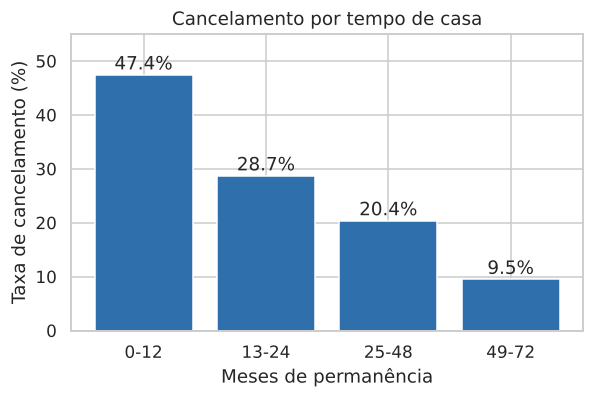

In [10]:
faixas = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
taxa_faixa = df.groupby(faixas, observed=True)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(taxa_faixa.index.astype(str), taxa_faixa.values, color=COR)
for i, v in enumerate(taxa_faixa.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylim(0, 55)
ax.set_xlabel("Meses de permanência")
ax.set_ylabel("Taxa de cancelamento (%)")
ax.set_title("Cancelamento por tempo de casa")
plt.show()

In [11]:
df[["tenure", "MonthlyCharges", "TotalCharges_num"]].corr().round(2)

,tenure,MonthlyCharges,TotalCharges_num
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges_num,0.83,0.65,1.00


### 3.4 Hipóteses iniciais

| # | Hipótese | Evidência |
|---|---|---|
| H1 | **Contrato mensal** é o principal fator de risco | 42,7% de cancelamento no contrato mensal, contra 11,3% (um ano) e 2,8% (dois anos) |
| H2 | **Clientes novos** cancelam muito mais | 47,4% nos primeiros 12 meses, contra 9,5% depois de 48 meses; mediana de permanência de 10 meses entre quem cancelou e 38 entre quem ficou |
| H3 | **Fibra óptica** concentra cancelamentos | 41,9% na fibra, contra 19,0% no DSL. Pode indicar problema de preço ou de qualidade percebida |
| H4 | **Mensalidade alta** aumenta o risco | Mediana de $ 79,65 entre quem cancelou e $ 64,43 entre quem ficou |
| H5 | **Serviços de suporte e segurança** protegem contra o cancelamento | 41,6% sem suporte técnico contra 15,2% com suporte; padrão igual para segurança online |
| H6 | **Pagamento por cheque eletrônico** está associado ao risco | 45,3%, contra 15% a 19% nas outras formas |
| H7 | **Gênero e telefonia** não diferenciam o risco | Taxas quase iguais entre as categorias |

São associações, não causas. Por exemplo, a fibra pode cancelar mais simplesmente por ser mais cara. O modelo vai considerar os atributos em conjunto.

`TotalCharges` tem correlação alta com `tenure` (0,83), o que é esperado: o total cobrado é aproximadamente permanência × mensalidade.

## 4. Verificação da qualidade dos dados

In [12]:
print("Valores nulos (NaN) na tabela:", int(df.drop(columns="TotalCharges_num").isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
print("customerID repetidos:", int(df["customerID"].duplicated().sum()))

Valores nulos (NaN) na tabela: 0
Linhas duplicadas: 0
customerID repetidos: 0


In [13]:
em_branco = df[df["TotalCharges"].str.strip() == ""]
print(f"Linhas com TotalCharges em branco: {len(em_branco)}")
print("Valores de tenure nessas linhas:", em_branco["tenure"].unique())
print("Clientes com tenure = 0 na base:", int((df["tenure"] == 0).sum()))
em_branco[["customerID", "tenure", "Contract", "MonthlyCharges", "TotalCharges", "Churn"]]

Linhas com TotalCharges em branco: 11
Valores de tenure nessas linhas: [0]
Clientes com tenure = 0 na base: 11


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.55,,No
753,3115-CZMZD,0,Two year,20.25,,No
936,5709-LVOEQ,0,Two year,80.85,,No
1082,4367-NUYAO,0,Two year,25.75,,No
1340,1371-DWPAZ,0,Two year,56.05,,No
3331,7644-OMVMY,0,Two year,19.85,,No
3826,3213-VVOLG,0,Two year,25.35,,No
4380,2520-SGTTA,0,Two year,20.00,,No
5218,2923-ARZLG,0,One year,19.70,,No
6670,4075-WKNIU,0,Two year,73.35,,No


In [14]:
# TotalCharges é coerente com tenure x MonthlyCharges?
com_fatura = df[df["tenure"] > 0]
razao = com_fatura["TotalCharges_num"] / (com_fatura["tenure"] * com_fatura["MonthlyCharges"])
print(razao.describe().round(3))
print(f"\nClientes com diferença maior que 20%: {int(((razao < 0.8) | (razao > 1.2)).sum())}")

count    7032.000
mean        1.000
std         0.051
min         0.689
25%         0.980
50%         1.000
75%         1.020
max         1.573
dtype: float64

Clientes com diferença maior que 20%: 59


In [15]:
# Os valores "No internet service" coincidem exatamente com InternetService = "No"?
sem_internet = df["InternetService"] == "No"
servicos = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
for coluna in servicos:
    assert ((df[coluna] == "No internet service") == sem_internet).all()
assert ((df["MultipleLines"] == "No phone service") == (df["PhoneService"] == "No")).all()
print(f"Clientes sem internet: {int(sem_internet.sum())}")
print("'No internet service' e 'No phone service' repetem exatamente a informação de InternetService e PhoneService.")

Clientes sem internet: 1526
'No internet service' e 'No phone service' repetem exatamente a informação de InternetService e PhoneService.


In [16]:
print("Faixas dos valores numéricos:")
print(df[["tenure", "MonthlyCharges", "TotalCharges_num"]].agg(["min", "max"]))

Faixas dos valores numéricos:
     tenure  MonthlyCharges  TotalCharges_num
min       0           18.25              18.8
max      72          118.75            8684.8


## Relatório de qualidade e encaminhamentos para a Fase 3

| # | Achado | Gravidade | Tratamento previsto |
|---|---|---|---|
| Q1 | `TotalCharges` lida como texto: 11 linhas com espaço em branco, todas de clientes com `tenure` = 0 (ainda sem fatura) | Média | Converter para número e preencher com 0 (permanência × mensalidade) |
| Q2 | `SeniorCitizen` codificada como 0/1, diferente das outras binárias | Baixa | Padronizar para Yes/No |
| Q3 | "No internet service" e "No phone service" repetem informação de outras colunas | Baixa | Unificar com "No" |
| Q4 | `TotalCharges` ≈ `tenure` × `MonthlyCharges` (razão mediana de 1,00). Em 59 clientes a diferença passa de 20%, o que é compatível com mudanças de plano ou de preço ao longo do tempo | Baixa | Manter os valores; testar na Fase 3 um atributo com a diferença entre a mensalidade atual e a média histórica |
| Q5 | Classes desbalanceadas (26,5% de cancelamentos) | Média | Divisão estratificada e métricas adequadas na Fase 4 |
| Q6 | `customerID` é um identificador sem valor preditivo | Baixa | Não usar como atributo do modelo |

Não há linhas duplicadas, identificadores repetidos, valores nulos explícitos nem valores numéricos fora de faixas plausíveis.

**Limitações da base, que voltam para a Fase 1:** não existem datas, histórico de atendimento, reclamações, uso dos serviços nem registros de ofertas de retenção. Por isso o retorno financeiro só pode ser simulado com premissas, como já previsto na avaliação de riscos. O escopo do projeto se mantém.